In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

print("Loading California Housing Dataset...")

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Loading California Housing Dataset...
Dataset loaded successfully!
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:

print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [3]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# First: reserve 20% for final testing
X_remaining, X_test, y_remaining, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Second: reserve 20% of the remaining data for calibration
X_train, X_cal, y_train, y_cal = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Calibration data:", X_cal.shape)
print("Testing data:", X_test.shape)


Training data: (13209, 8)
Calibration data: (3303, 8)
Testing data: (4128, 8)


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Create the models
lr_model = LinearRegression()
dt_model = DecisionTreeRegressor(random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the models
lr_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {
    "Linear Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

for name, model in models.items():
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    print("\n", name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


 Linear Regression
MAE: 0.533473818785623
MSE: 0.5544725485137042
RMSE: 0.7446291348810522
R2 Score: 0.5768706123655905

 Decision Tree
MAE: 0.479475695251938
MSE: 0.556560730323813
RMSE: 0.7460299795074009
R2 Score: 0.5752770779463499

 Random Forest
MAE: 0.3367361859980621
MSE: 0.2655065583051227
RMSE: 0.5152732850683438
R2 Score: 0.7973864932904076


In [6]:

import numpy as np

# Predict house values using the calibration dataset
cal_predictions = rf_model.predict(X_cal)

# Calculate absolute prediction errors
cal_errors = np.abs(y_cal - cal_predictions)

# Set the desired coverage level
confidence_level = 0.90

# Calculate the conformal calibration threshold
n = len(cal_errors)

q_level = np.ceil((n + 1) * confidence_level) / n

q_level = min(q_level, 1.0)

calibration_threshold = np.quantile(
    cal_errors,
    q_level,
    method="higher"
)

print("Calibration samples:", n)
print("Target interval coverage:", confidence_level * 100, "%")
print("Calibration error threshold:", round(calibration_threshold, 4))


Calibration samples: 3303
Target interval coverage: 90.0 %
Calibration error threshold: 0.813


In [7]:
test_predictions = rf_model.predict(X_test)

lower_bounds = test_predictions - calibration_threshold
upper_bounds = test_predictions + calibration_threshold

test_coverage = np.mean(
    (y_test >= lower_bounds) & (y_test <= upper_bounds)
)

print("Test interval coverage:", round(test_coverage * 100, 2), "%")
print("Average interval width:", round(2 * calibration_threshold, 4))

Test interval coverage: 90.12 %
Average interval width: 1.626


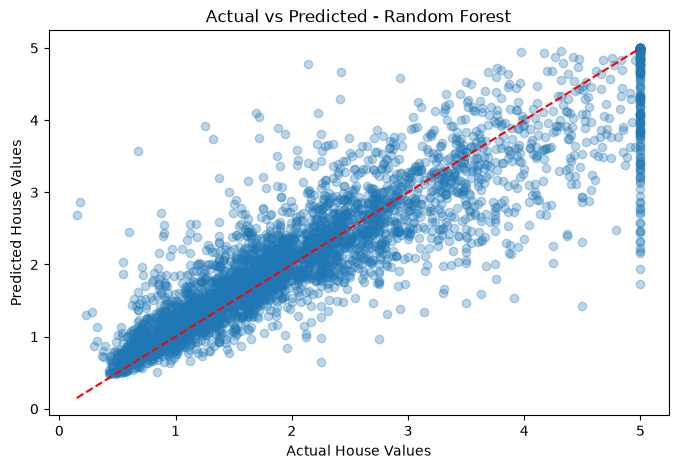

In [8]:
import matplotlib.pyplot as plt

# Get predictions from all models
lr_pred = lr_model.predict(X_test)
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Compare actual and predicted values
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_pred, alpha=0.3)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted - Random Forest")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

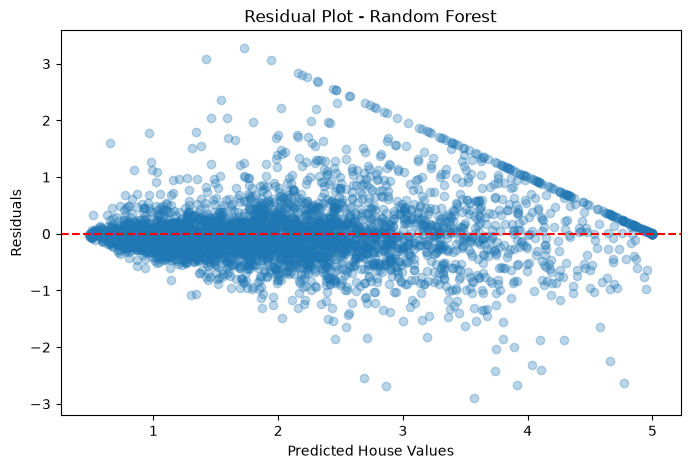

In [9]:
# Calculate residuals
residuals = y_test - rf_pred

# Plot residuals
plt.figure(figsize=(8, 5))

plt.scatter(rf_pred, residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")
plt.title("Residual Plot - Random Forest")

plt.show()

      Feature  Importance
0      MedInc    0.527782
5    AveOccup    0.134961
6    Latitude    0.087875
7   Longitude    0.087687
1    HouseAge    0.056988
2    AveRooms    0.044092
4  Population    0.030888
3   AveBedrms    0.029726


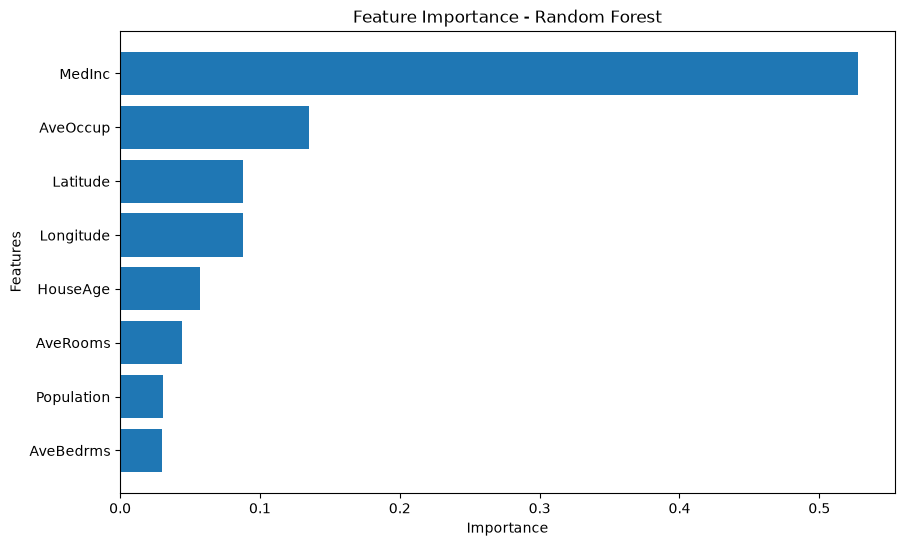

In [10]:
# Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Feature Importance - Random Forest")
plt.gca().invert_yaxis()
plt.show()

In [11]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, "california_housing_model.pkl")

print("Model saved successfully!")

Model saved successfully!


## Conclusion

In this project, we developed a machine learning model to predict California housing prices using the California Housing dataset.

We trained and evaluated three regression algorithms:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

The models were evaluated using MAE, MSE, RMSE, and R² score. We also visualized the actual vs. predicted values, residuals, and feature importance.

Based on the evaluation results, the best-performing model was selected and saved using Joblib for future predictions.

The project demonstrates how machine learning can be used to analyze housing data and estimate median house values. However, the predictions are estimates and may not represent the exact market price of an individual property.

In [12]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, "california_housing_model.pkl")

# Save the calibration threshold
joblib.dump(calibration_threshold, "calibration_threshold.pkl")

print("Model and calibration threshold saved successfully!")

Model and calibration threshold saved successfully!


In [13]:
import gzip
import shutil

with open("../california_housing_model.pkl", "rb") as f_in:
    with gzip.open("../california_housing_model_compressed.pkl.gz", "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

print("California model compressed successfully!")

California model compressed successfully!
